# 10 — GHSL GHS-BUILT-C validation EDA (before the comparison model)

**Why this notebook exists.** Before trusting a GHSL-vs-model scoreboard, we need to know
what we are comparing: the raster product, the GT contract, the spatial grid rules, and
the two different benchmarks in [`docs/ghsl_validation_pipeline.md`](../docs/ghsl_validation_pipeline.md).

Notebook 09 is **Degree of Urbanization** (GHS-SMOD, a stratifier). This notebook is
**GHS-BUILT-C FUN** — the 10 m residential / non-residential product we will score against.

**Mental model (from the pipeline doc)**

| Rule | Meaning |
|---|---|
| Same locations | Score GHSL and our model only where GT buildings exist |
| Same labels | Binary `RES` / `NRES` only; never silently remap `MIXED` / `UNKNOWN` |
| Same spatial support | Use the GHSL 10 m Mollweide grid — do not invent a new grid |
| Categorical raster | **Never** bilinearly interpolate GHSL |
| Two benchmarks | (A) functional classification when GHSL predicts RES/NRES; (B) end-to-end including abstentions (`0` / `255`) |

**Data this notebook reads**

- `data/ghsl/tiles/*.tif` — GHS-BUILT-C FUN 2018, 10 m, ESRI:54009
- `data/validation/gt_buildings.parquet` — building GT (`RES`/`NRES`)
- `data/predictions/model_predictions.parquet` — optional model preds (for side-by-side EDA)
- `outputs/validation/per_building_predictions.parquet` — if present, reuse building×GHSL joins

**Writes.** `outputs/ghsl_eda/` (plots + `snapshot.json` + summary tables).

**Does not train a model.** Exploration only.


## 0. Setup


In [1]:
from __future__ import annotations

import json
import os
import sys
import warnings
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

%matplotlib inline

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from IPython.display import display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from rasterio.windows import from_bounds
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", lambda x: f"{x:0.4f}")

ROOT = Path(".").resolve()
# nbconvert may start with cwd = notebooks/; walk up to the repo that has validation/
for cand in [ROOT, *ROOT.parents]:
    if (cand / "validation" / "config.yaml").exists():
        ROOT = cand
        break
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

from validation.io import audit_gt, load_config, load_gt_buildings, load_predictions
from validation.ghsl import parse_tile_rc
from validation.schemas import GHSL_TO_LABEL
from validation.spatial import to_ghsl_crs

OUT = ROOT / "outputs" / "ghsl_eda"
OUT.mkdir(parents=True, exist_ok=True)
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

cfg = load_config()
N_WORKERS = os.cpu_count() or 8
print("repo", ROOT)
print("CPU workers", N_WORKERS)
print("GHSL tiles dir", cfg["paths"]["ghsl_tiles_dir"])
print("GT path", cfg["paths"]["gt_buildings"])
print("output", OUT)


repo /data/users/kv133/Alpha-Earth-Embeddings-Research
CPU workers 80
GHSL tiles dir /data/users/kv133/Alpha-Earth-Embeddings-Research/data/ghsl/tiles
GT path /data/users/kv133/Alpha-Earth-Embeddings-Research/data/validation/gt_buildings.parquet
output /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/ghsl_eda


## 1. What product are we working with?

Pipeline §1 / config: **GHS-BUILT-C FUN**, year **2018**, **10 m**, CRS **World Mollweide / ESRI:54009**.

| Raster value | Meaning | Validation label |
|---:|---|---|
| 0 | non-built | `NONBUILT` (abstention in end-to-end) |
| 1 | residential | `RES` |
| 2 | non-residential | `NRES` |
| 255 | nodata | `NODATA` (abstention) |

Hard rules from the doc:

1. Treat this as a **categorical** map — nearest-neighbor only.
2. Do **not** replace `0` with RES.
3. Do **not** resample GHSL onto a homemade 10 m grid; read *its* transform / origin.


In [2]:
GHSL_COLORS = {
    0: "#dfe6e9",    # non-built
    1: "#27ae60",    # residential
    2: "#e67e22",    # non-residential
    255: "#2c3e50",  # nodata
}
GHSL_NAMES = {0: "non-built (0)", 1: "RES (1)", 2: "NRES (2)", 255: "nodata (255)"}

tiles = sorted(Path(cfg["paths"]["ghsl_tiles_dir"]).glob("GHS_BUILT_C_FUN_*.tif"))
assert tiles, "No GHSL tiles found — run validation tile download first"

rows = []
for p in tiles:
    rc = parse_tile_rc(p)
    with rasterio.open(p) as ds:
        rows.append({
            "tile": p.name,
            "row": None if rc is None else rc[0],
            "col": None if rc is None else rc[1],
            "crs": str(ds.crs),
            "res_x": float(ds.res[0]),
            "res_y": float(ds.res[1]),
            "width": ds.width,
            "height": ds.height,
            "dtype": ds.dtypes[0],
            "nodata": ds.nodata,
            "minx": ds.bounds.left,
            "miny": ds.bounds.bottom,
            "maxx": ds.bounds.right,
            "maxy": ds.bounds.top,
            "bytes_gb": p.stat().st_size / 1e9,
        })

tile_meta = pd.DataFrame(rows)
display(tile_meta)

# Sanity: one product, one CRS, 10 m categorical bytes
assert (tile_meta["crs"] == "ESRI:54009").all()
assert (tile_meta["res_x"] == 10.0).all() and (tile_meta["res_y"] == 10.0).all()
assert (tile_meta["dtype"] == "uint8").all()
print("✓ all tiles are ESRI:54009 / 10 m / uint8 categorical")
print(f"n_tiles={len(tile_meta)}  footprint≈{tile_meta.bytes_gb.sum():.2f} GB on disk")
tile_meta.to_csv(OUT / "tile_inventory.csv", index=False)


,tile,row,col,crs,res_x,res_y,width,height,dtype,nodata,minx,miny,maxx,maxy,bytes_gb
0,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,4,11,ESRI:54009,10.0000,10.0000,100000,100000,uint8,255.0000,-8041000.0000,5000000.0000,-7041000.0000,6000000.0000,0.0985
1,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,4,13,ESRI:54009,10.0000,10.0000,100000,100000,uint8,255.0000,-6041000.0000,5000000.0000,-5041000.0000,6000000.0000,0.0686
2,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,4,9,ESRI:54009,10.0000,10.0000,100000,100000,uint8,255.0000,-10041000.0000,5000000.0000,-9041000.0000,6000000.0000,0.0613
3,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,5,10,ESRI:54009,10.0000,10.0000,100000,100000,uint8,255.0000,-9041000.0000,4000000.0000,-8041000.0000,5000000.0000,0.0993
4,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,5,11,ESRI:54009,10.0000,10.0000,100000,100000,uint8,255.0000,-8041000.0000,4000000.0000,-7041000.0000,5000000.0000,0.1895
5,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,5,12,ESRI:54009,10.0000,10.0000,100000,100000,uint8,255.0000,-7041000.0000,4000000.0000,-6041000.0000,5000000.0000,0.1340
6,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,5,8,ESRI:54009,10.0000,10.0000,80000,100000,uint8,255.0000,-10841000.0000,4000000.0000,-10041000.0000,5000000.0000,0.0588
7,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,5,9,ESRI:54009,10.0000,10.0000,100000,100000,uint8,255.0000,-10041000.0000,4000000.0000,-9041000.0000,5000000.0000,0.0536
8,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,6,10,ESRI:54009,10.0000,10.0000,100000,70000,uint8,255.0000,-9041000.0000,3300000.0000,-8041000.0000,4000000.0000,0.0769


✓ all tiles are ESRI:54009 / 10 m / uint8 categorical
n_tiles=9  footprint≈0.84 GB on disk


## 2. Value histograms across tiles (what the map actually contains)

Most of each 1000 km tile is ocean / non-built. We still need the **built** class mix,
because that is what validation will compare against GT roofs.


loaded cached /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/ghsl_eda/tile_value_histograms.csv


,tile,n_0,n_1,n_2,n_255,frac_1,frac_2
0,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,9758722500,231500000,9777500,0,0.0232,0.0010
1,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,8769832500,125527500,4640000,1100000000,0.0126,0.0005
2,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,8674575000,120575000,4850000,1200000000,0.0121,0.0005
3,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,9764295000,226920000,8785000,0,0.0227,0.0009
4,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,9367557500,610672500,21770000,0,0.0611,0.0022
5,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,5427742500,455687500,16570000,4100000000,0.0456,0.0017
6,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,6300167500,186295000,13537500,1500000000,0.0233,0.0017
7,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,9916342500,80337500,3320000,0,0.0080,0.0003
8,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,4967777500,221785000,10437500,1800000000,0.0317,0.0015


built pixels across mosaic: RES 2259300000 NRES 93687500 RES share among built 0.9601835963854461


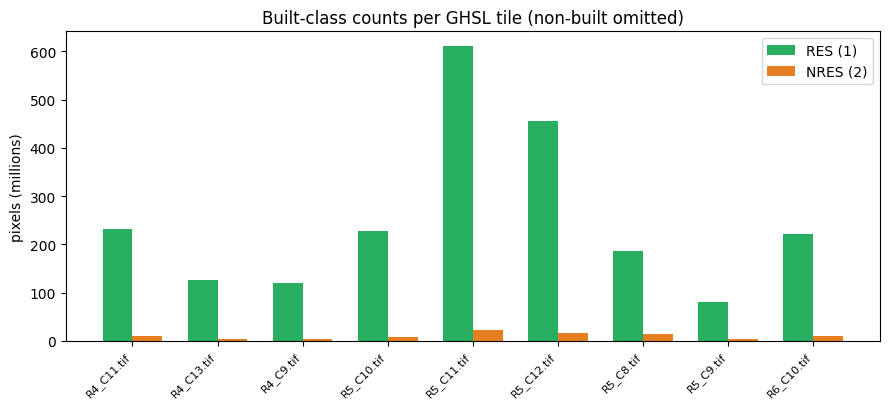

In [3]:
def _hist_one(path_str: str, max_dim: int = 2000) -> dict:
    """Approximate class counts via nearest-neighbor downsample (EDA only).

    Full 100k×100k tiles are ~10¹⁰ pixels each — too heavy for interactive EDA.
    Nearest-neighbor preserve categorical codes; counts are scaled back to full-res
    so bar heights are comparable across tiles. Exact building-level stats come later.
    """
    from pathlib import Path

    import numpy as np
    import rasterio
    from rasterio.enums import Resampling

    path = Path(path_str)
    with rasterio.open(path) as ds:
        scale = max(ds.height / max_dim, ds.width / max_dim, 1.0)
        out_h = max(1, int(round(ds.height / scale)))
        out_w = max(1, int(round(ds.width / scale)))
        a = ds.read(1, out_shape=(out_h, out_w), resampling=Resampling.nearest)
        factor = (ds.height * ds.width) / a.size
        u, c = np.unique(a, return_counts=True)
        counts = {int(k): int(v * factor) for k, v in zip(u.tolist(), c.tolist())}
        out = {
            "tile": path.name,
            "sample_h": out_h,
            "sample_w": out_w,
            "downsample_factor_px": float(scale),
        }
    for k in (0, 1, 2, 255):
        out[f"n_{k}"] = int(counts.get(k, 0))
    out["n_other"] = int(sum(v for k, v in counts.items() if k not in (0, 1, 2, 255)))
    out["n_total"] = int(sum(counts.values()))
    return out


hist_path = OUT / "tile_value_histograms.csv"
if hist_path.exists():
    hist = pd.read_csv(hist_path)
    print("loaded cached", hist_path)
else:
    paths = [str(p) for p in tiles]
    rows = []
    with ProcessPoolExecutor(max_workers=min(N_WORKERS, len(paths))) as pool:
        futs = {pool.submit(_hist_one, p): p for p in paths}
        for fut in tqdm(as_completed(futs), total=len(futs), desc="tile histograms (downsampled)"):
            rows.append(fut.result())
    hist = pd.DataFrame(rows).sort_values("tile").reset_index(drop=True)
    hist.to_csv(hist_path, index=False)
    print("note: tile histograms are nearest-neighbor downsampled approximations")

for k in (0, 1, 2, 255):
    hist[f"frac_{k}"] = hist[f"n_{k}"] / hist["n_total"]

display(hist[["tile", "n_0", "n_1", "n_2", "n_255", "frac_1", "frac_2"]])

built = hist[["n_1", "n_2"]].sum()
print("built pixels across mosaic: RES", int(built["n_1"]), "NRES", int(built["n_2"]),
      "RES share among built", float(built["n_1"] / (built["n_1"] + built["n_2"])))

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(hist))
w = 0.35
ax.bar(x - w / 2, hist["n_1"] / 1e6, width=w, color=GHSL_COLORS[1], label="RES (1)")
ax.bar(x + w / 2, hist["n_2"] / 1e6, width=w, color=GHSL_COLORS[2], label="NRES (2)")
ax.set_xticks(x)
ax.set_xticklabels([t.replace("GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1_0_", "") for t in hist["tile"]],
                   rotation=45, ha="right", fontsize=8)
ax.set_ylabel("pixels (millions)")
ax.set_title("Built-class counts per GHSL tile (non-built omitted)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "tile_built_class_counts.png", dpi=140)
plt.show()


## 3. Ground-truth audit (pipeline §4)

Before scoring anything, audit the GT table the validation runner expects:

`building_id`, `aoi_id`, `geometry`, `label`, plus optional `confidence` / `source`.

Primary binary benchmark uses **only** `RES` and `NRES`.


{
  "n_aois": 10,
  "n_buildings": 11280,
  "label_counts": {
    "NRES": 8191,
    "RES": 3089
  },
  "n_binary": 11280,
  "class_balance_res": 0.2738475177304965,
  "buildings_per_aoi": {
    "Atlanta_SE": 1018,
    "Boston_NE": 1370,
    "Chicago_MW": 1321,
    "Denver_W": 1126,
    "Houston_S": 1171,
    "LA_W": 1027,
    "NYC_NE": 1327,
    "Phoenix_SW": 1080,
    "SF_W": 805,
    "Seattle_NW": 1035
  },
  "n_duplicate_geometries": 0,
  "crs": "EPSG:4326"
}
model predictions 11280 overlap 11280


,n,n_res,n_nres,frac_res
aoi_id,,,,
Boston_NE,1370,404,966,0.2949
NYC_NE,1327,337,990,0.2540
Chicago_MW,1321,349,972,0.2642
Houston_S,1171,325,846,0.2775
Denver_W,1126,316,810,0.2806
Phoenix_SW,1080,308,772,0.2852
Seattle_NW,1035,344,691,0.3324
LA_W,1027,185,842,0.1801
Atlanta_SE,1018,318,700,0.3124


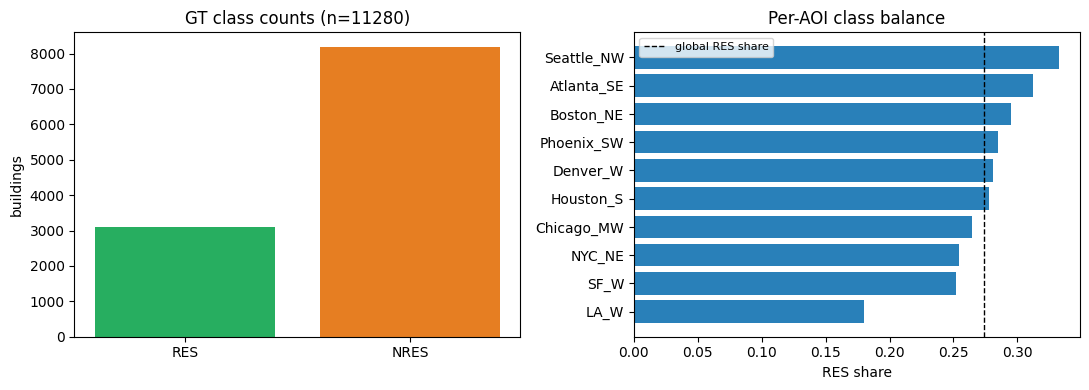

duplicate building_id 0
invalid geoms 0
CRS EPSG:4326


In [4]:
gt = load_gt_buildings(cfg["paths"]["gt_buildings"], cfg)
audit = audit_gt(gt, cfg)
print(json.dumps(audit, indent=2))
(OUT / "dataset_audit.json").write_text(json.dumps(audit, indent=2))

pred_path = Path(cfg["paths"]["model_predictions"])
preds = load_predictions(pred_path) if pred_path.exists() else None
if preds is not None:
    print("model predictions", len(preds), "overlap", len(set(gt.building_id) & set(preds.building_id)))
else:
    print("model predictions not found — EDA will focus on GHSL × GT only")

# Per-AOI balance
aoi = (
    gt.groupby("aoi_id")
    .agg(n=("building_id", "size"), n_res=("label", lambda s: int((s == "RES").sum())))
    .assign(n_nres=lambda d: d["n"] - d["n_res"], frac_res=lambda d: d["n_res"] / d["n"])
    .sort_values("n", ascending=False)
)
display(aoi)
aoi.to_csv(OUT / "gt_per_aoi_balance.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(["RES", "NRES"], [audit["label_counts"].get("RES", 0), audit["label_counts"].get("NRES", 0)],
            color=["#27ae60", "#e67e22"])
axes[0].set_title(f"GT class counts (n={audit['n_buildings']})")
axes[0].set_ylabel("buildings")

aoi_plot = aoi.sort_values("frac_res")
axes[1].barh(aoi_plot.index, aoi_plot["frac_res"], color="#2980b9")
axes[1].axvline(audit["class_balance_res"], color="k", ls="--", lw=1, label="global RES share")
axes[1].set_xlabel("RES share")
axes[1].set_title("Per-AOI class balance")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "gt_class_balance.png", dpi=140)
plt.show()

print("duplicate building_id", int(gt.building_id.duplicated().sum()))
print("invalid geoms", int((~gt.geometry.is_valid).sum()))
print("CRS", gt.crs)


## 4. Spatial support — reproject GT onto the GHSL grid (pipeline §6)

Pixel validation must use **ESRI:54009** and the GHSL raster's exact transform.
We do not construct an independent 10 m grid.

Here we only check that every AOI lands on a downloaded tile after reprojection.


In [5]:
gt_m = to_ghsl_crs(gt)
print("reprojected CRS", gt_m.crs)

# Which tile covers each building centroid?
def tile_for_xy(x: float, y: float, meta: pd.DataFrame) -> str | None:
    hit = meta[(meta.minx <= x) & (x < meta.maxx) & (meta.miny <= y) & (y < meta.maxy)]
    if hit.empty:
        return None
    return hit.iloc[0]["tile"]

cent = gt_m.geometry.centroid
gt_m = gt_m.assign(
    cx=cent.x,
    cy=cent.y,
    tile=[tile_for_xy(x, y, tile_meta) for x, y in zip(cent.x, cent.y)],
)
missing_tile = gt_m["tile"].isna().sum()
print("buildings with no covering local tile:", int(missing_tile))
cov = gt_m.groupby(["aoi_id", "tile"], dropna=False).size().rename("n").reset_index()
display(cov)
cov.to_csv(OUT / "buildings_per_aoi_tile.csv", index=False)
assert missing_tile == 0, "Download missing GHSL tiles before running validation"
print("✓ every GT building centroid falls inside a local tile")


reprojected CRS ESRI:54009


buildings with no covering local tile: 0


,aoi_id,tile,n
0,Atlanta_SE,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,1018
1,Boston_NE,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,1370
2,Chicago_MW,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,489
3,Chicago_MW,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,832
4,Denver_W,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,1126
5,Houston_S,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,1171
6,LA_W,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,1027
7,NYC_NE,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,1327
8,Phoenix_SW,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,136
9,Phoenix_SW,GHS_BUILT_C_FUN_E2018_GLOBE_R2023A_54009_10_V1...,944


✓ every GT building centroid falls inside a local tile


## 5. Building-level GHSL labels (what validation actually samples)

The building evaluator rasterizes each footprint onto the GHSL window and takes an
**area-weighted majority** among RES/NRES pixels (`validation/building_eval.py`).
If only non-built / nodata are present → abstention.

If `outputs/validation/per_building_predictions.parquet` exists we reuse it; otherwise
we sample a stratified subset live (full recompute is the validation runner's job).


In [6]:
pb_path = ROOT / "outputs" / "validation" / "per_building_predictions.parquet"
if pb_path.exists():
    pb = pd.read_parquet(pb_path)
    print("loaded", pb_path, "n=", len(pb))
else:
    raise FileNotFoundError(
        f"{pb_path} missing. Run: .venv/bin/python validation/run_validation.py --skip-bootstrap"
    )

# Join GT for safety
pb = pb.merge(gt[["building_id", "label"]].rename(columns={"label": "gt_check"}), on="building_id", how="left")
assert (pb["gt_label"] == pb["gt_check"]).all()

print("GHSL prediction mix:")
display(pb["ghsl_prediction"].value_counts(dropna=False).to_frame("n"))
print("coverage (RES/NRES):", float(pb["ghsl_covered"].mean()))

# Confusion vs GT on covered buildings
covered = pb[pb["ghsl_covered"]].copy()
ct = pd.crosstab(covered["gt_label"], covered["ghsl_prediction"], margins=True)
display(ct)
ct.to_csv(OUT / "ghsl_vs_gt_confusion_building.csv")

def _bin_metrics(y_true, y_pred, pos="RES"):
    yt = np.asarray(y_true) == pos
    yp = np.asarray(y_pred) == pos
    tp = int((yt & yp).sum()); fp = int((~yt & yp).sum())
    fn = int((yt & ~yp).sum()); tn = int((~yt & ~yp).sum())
    prec = tp / (tp + fp) if tp + fp else float("nan")
    rec = tp / (tp + fn) if tp + fn else float("nan")
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else float("nan")
    acc = (tp + tn) / max(tp + tn + fp + fn, 1)
    return dict(n=len(y_true), accuracy=acc, res_precision=prec, res_recall=rec, res_f1=f1)

m_ghsl = _bin_metrics(covered["gt_label"], covered["ghsl_prediction"])
m_model = _bin_metrics(pb["gt_label"], pb["model_prediction"]) if "model_prediction" in pb.columns else None
print("GHSL (functional / covered):", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in m_ghsl.items()})
if m_model:
    print("Model (all buildings):     ", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in m_model.items()})


loaded /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/validation/per_building_predictions.parquet n= 11280
GHSL prediction mix:


,n
ghsl_prediction,
RES,6415
NRES,4789
NONBUILT,76


coverage (RES/NRES): 0.9932624113475177


ghsl_prediction,NRES,RES,All
gt_label,,,
NRES,4668,3478,8146
RES,121,2937,3058
All,4789,6415,11204


GHSL (functional / covered): {'n': 11204, 'accuracy': 0.6788, 'res_precision': 0.4578, 'res_recall': 0.9604, 'res_f1': 0.6201}
Model (all buildings):      {'n': 11280, 'accuracy': 0.7986, 'res_precision': 0.6404, 'res_recall': 0.6031, 'res_f1': 0.6212}


## 6. Two benchmarks, with real numbers (pipeline §10)

### A. Functional classification
> When GHSL provides a RES/NRES call, how accurate is it?

Filter: `GT ∈ {RES,NRES}` **and** `GHSL ∈ {RES,NRES}`.

### B. End-to-end
> For known GT buildings, how often does the *system* produce the correct class?

`NONBUILT` / `NODATA` count as **abstentions**, not silent discards. Report coverage,
selective accuracy (among covered), and effective accuracy (abstention = wrong / miss).


,system,benchmark,n,coverage,selective_accuracy,effective_accuracy,accuracy,res_precision,res_recall,res_f1
0,GHSL,functional(=e2e selective here),11204,0.9933,0.6788,0.6742,0.6788,0.4578,0.9604,0.6201
1,model,end_to_end,11280,1.0000,0.7986,0.7986,0.7986,0.6404,0.6031,0.6212


,aoi_id,n,ghsl_coverage,ghsl_selective_acc,model_acc,gt_frac_res,ghsl_frac_res
5,LA_W,1027,0.9922,0.5643,0.7790,0.1801,0.5937
1,Boston_NE,1370,0.9927,0.5882,0.8102,0.2949,0.6779
2,Chicago_MW,1321,0.9962,0.6421,0.8372,0.2642,0.6003
6,NYC_NE,1327,0.9925,0.6629,0.7882,0.2540,0.5763
0,Atlanta_SE,1018,0.9843,0.6717,0.7151,0.3124,0.6028
8,SF_W,805,0.9925,0.6796,0.8373,0.2522,0.5419
4,Houston_S,1171,0.9923,0.6833,0.7857,0.2775,0.5731
7,Phoenix_SW,1080,0.9935,0.7064,0.8148,0.2852,0.5713
9,Seattle_NW,1035,0.9990,0.7398,0.7952,0.3324,0.5590
3,Denver_W,1126,0.9964,0.8725,0.8179,0.2806,0.3966


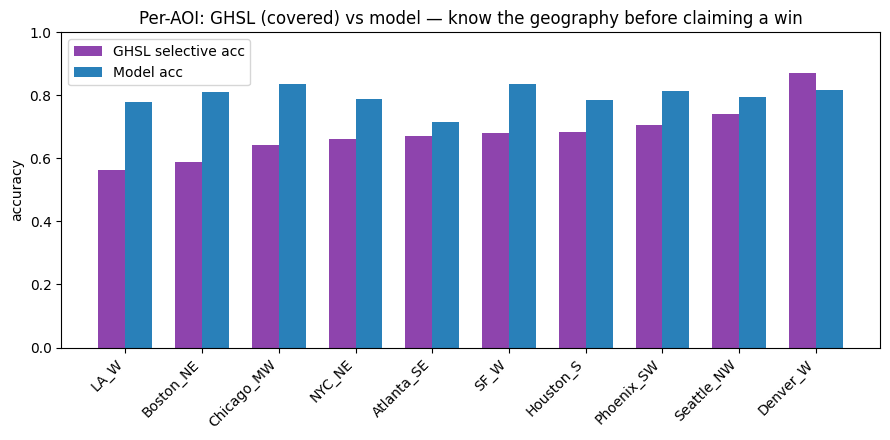

In [7]:
def end_to_end(df: pd.DataFrame, pred_col: str, covered_col: str) -> dict:
    n = len(df)
    cov = float(df[covered_col].mean())
    covered = df[df[covered_col]]
    selective = float((covered[pred_col] == covered["gt_label"]).mean()) if len(covered) else float("nan")
    # abstention counts as incorrect for effective accuracy
    correct = ((df[covered_col]) & (df[pred_col] == df["gt_label"])).sum()
    effective = float(correct / n) if n else float("nan")
    return dict(n=n, coverage=cov, selective_accuracy=selective, effective_accuracy=effective)

fun = end_to_end(pb.assign(ghsl_covered=pb["ghsl_covered"]), "ghsl_prediction", "ghsl_covered")
# For model, covered is always True in current prep
pb = pb.assign(model_covered=True if "model_covered" not in pb.columns else pb["model_covered"])
e2e_ghsl = fun
e2e_model = end_to_end(pb, "model_prediction", "model_covered")

summary = pd.DataFrame([
    {"system": "GHSL", "benchmark": "functional(=e2e selective here)", **e2e_ghsl, **m_ghsl},
    {"system": "model", "benchmark": "end_to_end", **e2e_model, **(m_model or {})},
])
display(summary)
summary.to_csv(OUT / "benchmark_summary.csv", index=False)

# Per-AOI slice — this is what you stare at before claiming a win
rows = []
for aoi_id, g in pb.groupby("aoi_id"):
    c = g[g["ghsl_covered"]]
    rows.append({
        "aoi_id": aoi_id,
        "n": len(g),
        "ghsl_coverage": float(g["ghsl_covered"].mean()),
        "ghsl_selective_acc": float((c["ghsl_prediction"] == c["gt_label"]).mean()) if len(c) else np.nan,
        "model_acc": float((g["model_prediction"] == g["gt_label"]).mean()),
        "gt_frac_res": float((g["gt_label"] == "RES").mean()),
        "ghsl_frac_res": float((c["ghsl_prediction"] == "RES").mean()) if len(c) else np.nan,
    })
per_aoi = pd.DataFrame(rows).sort_values("ghsl_selective_acc")
display(per_aoi)
per_aoi.to_csv(OUT / "per_aoi_ghsl_vs_model.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(per_aoi))
w = 0.35
ax.bar(x - w / 2, per_aoi["ghsl_selective_acc"], width=w, color="#8e44ad", label="GHSL selective acc")
ax.bar(x + w / 2, per_aoi["model_acc"], width=w, color="#2980b9", label="Model acc")
ax.set_xticks(x)
ax.set_xticklabels(per_aoi["aoi_id"], rotation=45, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("accuracy")
ax.set_title("Per-AOI: GHSL (covered) vs model — know the geography before claiming a win")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "per_aoi_ghsl_vs_model.png", dpi=140)
plt.show()


## 6b. CNN vs GHSL — macro-F1 + RES as positive

Headline comparison uses **macro-F1** (mean of RES and NRES one-vs-rest F1).
Precision / recall / residential F1 still use **RES = positive** (no NRES-as-positive panel).

Writes:

- `outputs/ghsl_eda/class_metrics_cnn_vs_ghsl.csv`
- `outputs/ghsl_eda/class_metrics_cnn_vs_ghsl_res_positive.csv`
- `outputs/ghsl_eda/per_aoi_class_metrics_cnn_vs_ghsl.csv`
- figures: `cnn_vs_ghsl_macro_f1.png`, `cnn_vs_ghsl_precision_recall.png`,
  `cnn_vs_ghsl_precision_recall_nres.png`, `cnn_vs_ghsl_precision_recall_f1.png`,
  `cnn_vs_ghsl_per_class_prf.png`, `cnn_vs_ghsl_per_aoi_prf.png`


,class_name,precision,recall,f1,support,system,scope
0,RES,0.4578,0.9604,0.6201,3058,GHSL,functional_covered
1,NRES,0.9747,0.5730,0.7218,8146,GHSL,functional_covered
2,macro,NaN,NaN,0.6709,11204,GHSL,functional_covered
3,RES,0.6409,0.6040,0.6219,3058,CNN,functional_covered
4,NRES,0.8545,0.8729,0.8636,8146,CNN,functional_covered
5,macro,NaN,NaN,0.7427,11204,CNN,functional_covered
6,RES,0.6404,0.6031,0.6212,3089,CNN,all_buildings
7,NRES,0.8535,0.8723,0.8628,8191,CNN,all_buildings
8,macro,NaN,NaN,0.7420,11280,CNN,all_buildings


,aoi_id,n,ghsl_res_p,ghsl_res_r,ghsl_res_f1,ghsl_macro_f1,cnn_res_p,cnn_res_r,cnn_res_f1,cnn_macro_f1
0,Atlanta_SE,1002,0.4801,0.9508,0.6381,0.6688,0.5407,0.4787,0.5078,0.6549
1,Boston_NE,1360,0.4132,0.9525,0.5764,0.5879,0.6320,0.8500,0.7249,0.7901
2,Chicago_MW,1316,0.4228,0.9570,0.5865,0.6355,0.6627,0.7937,0.7223,0.8040
3,Denver_W,1122,0.6921,0.9809,0.8116,0.8576,0.6934,0.6338,0.6622,0.7693
4,Houston_S,1162,0.4655,0.9627,0.6275,0.6760,0.7403,0.3540,0.4790,0.6724
5,LA_W,1019,0.2843,0.9399,0.4365,0.5407,0.4404,0.7869,0.5647,0.7097
6,NYC_NE,1317,0.4282,0.9701,0.5941,0.6529,0.6120,0.4567,0.5231,0.6935
7,Phoenix_SW,1073,0.4927,0.9869,0.6572,0.7003,0.8418,0.4346,0.5733,0.7278
8,SF_W,799,0.4365,0.9403,0.5962,0.6653,0.8515,0.4279,0.5695,0.7346
9,Seattle_NW,1034,0.5640,0.9504,0.7079,0.7367,0.6728,0.7434,0.7064,0.7744


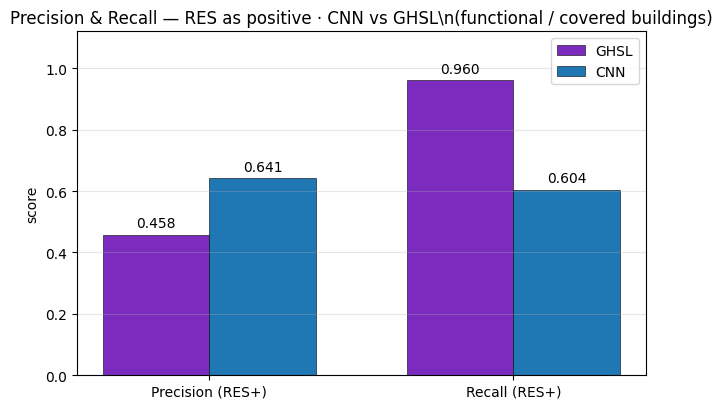

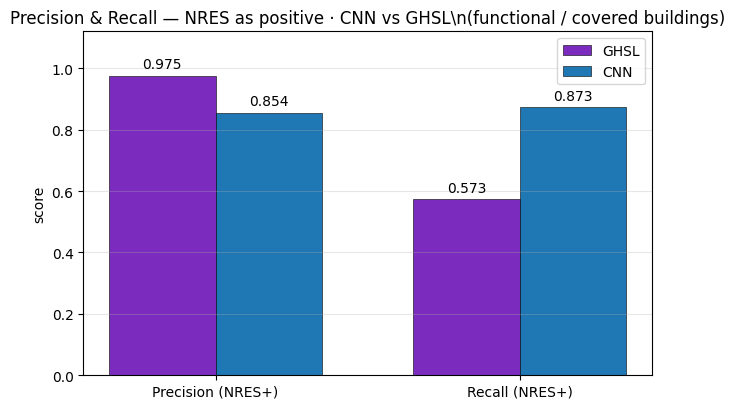

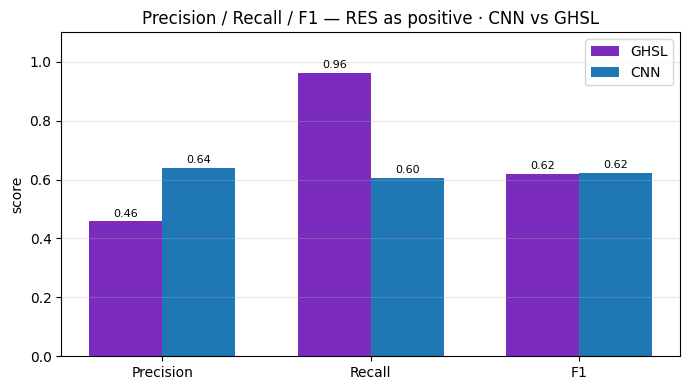

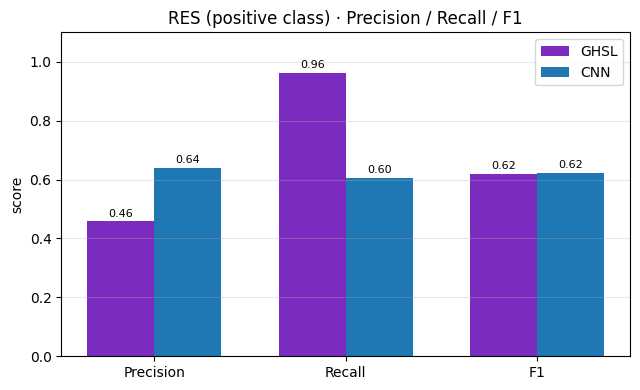

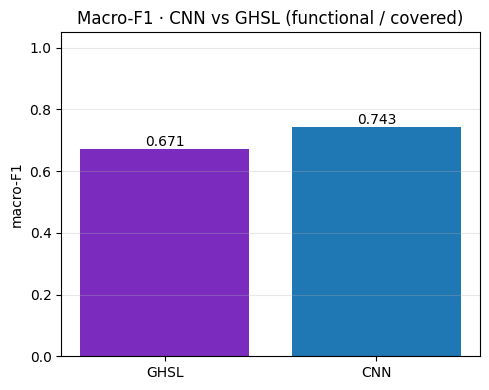

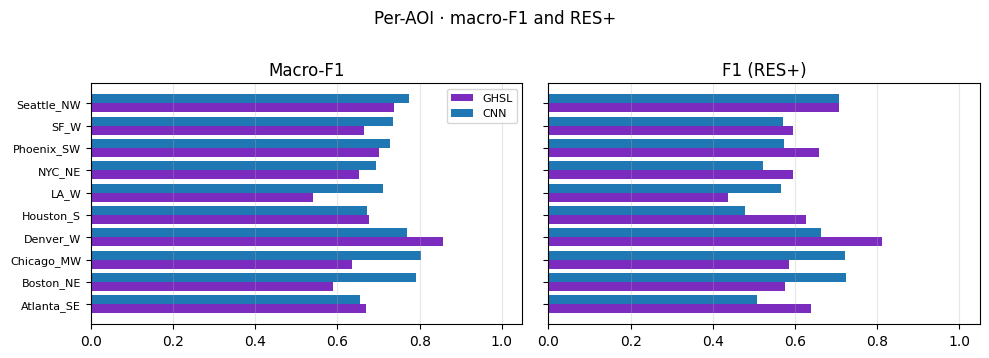

Wrote macro-F1 + RES+ CNN vs GHSL tables + figures under /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/ghsl_eda


In [8]:
from sklearn.metrics import precision_recall_fscore_support, f1_score

CNN_COLOR = "#1f77b4"
GHSL_COLOR = "#7b2cbf"


def _res_positive_row(y_true, y_pred, system: str, scope: str) -> dict:
    yt = np.asarray(y_true).astype(str)
    yp = np.asarray(y_pred).astype(str)
    p, r, f, _ = precision_recall_fscore_support(
        yt, yp, labels=["RES"], average=None, zero_division=0
    )
    return {
        "class_name": "RES",
        "precision": float(p[0]),
        "recall": float(r[0]),
        "f1": float(f[0]),
        "support": int((yt == "RES").sum()),
        "system": system,
        "scope": scope,
    }


def _nres_positive_row(y_true, y_pred, system: str, scope: str) -> dict:
    yt = np.asarray(y_true).astype(str)
    yp = np.asarray(y_pred).astype(str)
    p, r, f, _ = precision_recall_fscore_support(
        yt, yp, labels=["NRES"], average=None, zero_division=0
    )
    return {
        "class_name": "NRES",
        "precision": float(p[0]),
        "recall": float(r[0]),
        "f1": float(f[0]),
        "support": int((yt == "NRES").sum()),
        "system": system,
        "scope": scope,
    }


def _macro_row(y_true, y_pred, system: str, scope: str) -> dict:
    yt = np.asarray(y_true).astype(str)
    yp = np.asarray(y_pred).astype(str)
    return {
        "class_name": "macro",
        "precision": float("nan"),
        "recall": float("nan"),
        "f1": float(f1_score(yt, yp, average="macro", zero_division=0)),
        "support": int(len(yt)),
        "system": system,
        "scope": scope,
    }


# Functional subset = GHSL covered (same buildings for both systems)
func = covered.copy()
rows_cls = [
    _res_positive_row(func["gt_label"], func["ghsl_prediction"], "GHSL", "functional_covered"),
    _nres_positive_row(func["gt_label"], func["ghsl_prediction"], "GHSL", "functional_covered"),
    _macro_row(func["gt_label"], func["ghsl_prediction"], "GHSL", "functional_covered"),
    _res_positive_row(func["gt_label"], func["model_prediction"], "CNN", "functional_covered"),
    _nres_positive_row(func["gt_label"], func["model_prediction"], "CNN", "functional_covered"),
    _macro_row(func["gt_label"], func["model_prediction"], "CNN", "functional_covered"),
    _res_positive_row(pb["gt_label"], pb["model_prediction"], "CNN", "all_buildings"),
    _nres_positive_row(pb["gt_label"], pb["model_prediction"], "CNN", "all_buildings"),
    _macro_row(pb["gt_label"], pb["model_prediction"], "CNN", "all_buildings"),
]
class_metrics = pd.DataFrame(rows_cls)
class_metrics.to_csv(OUT / "class_metrics_cnn_vs_ghsl.csv", index=False)
class_metrics[class_metrics["class_name"] == "RES"].to_csv(
    OUT / "class_metrics_cnn_vs_ghsl_res_positive.csv", index=False
)
class_metrics[class_metrics["class_name"] == "NRES"].to_csv(
    OUT / "class_metrics_cnn_vs_ghsl_nres_positive.csv", index=False
)
display(class_metrics)

# Per-AOI RES+ + macro-F1
aoi_rows = []
for aoi_id, g in func.groupby("aoi_id"):
    gh = _res_positive_row(g["gt_label"], g["ghsl_prediction"], "GHSL", aoi_id)
    cn = _res_positive_row(g["gt_label"], g["model_prediction"], "CNN", aoi_id)
    aoi_rows.append({
        "aoi_id": aoi_id,
        "n": len(g),
        "ghsl_res_p": gh["precision"],
        "ghsl_res_r": gh["recall"],
        "ghsl_res_f1": gh["f1"],
        "ghsl_macro_f1": float(f1_score(g["gt_label"], g["ghsl_prediction"], average="macro", zero_division=0)),
        "cnn_res_p": cn["precision"],
        "cnn_res_r": cn["recall"],
        "cnn_res_f1": cn["f1"],
        "cnn_macro_f1": float(f1_score(g["gt_label"], g["model_prediction"], average="macro", zero_division=0)),
    })
per_aoi_res = pd.DataFrame(aoi_rows).sort_values("aoi_id")
per_aoi_res.to_csv(OUT / "per_aoi_class_metrics_cnn_vs_ghsl.csv", index=False)
display(per_aoi_res)

res_fun = class_metrics[
    (class_metrics["scope"] == "functional_covered") & (class_metrics["class_name"] == "RES")
].set_index("system")
nres_fun = class_metrics[
    (class_metrics["scope"] == "functional_covered") & (class_metrics["class_name"] == "NRES")
].set_index("system")
macro_fun = class_metrics[
    (class_metrics["scope"] == "functional_covered") & (class_metrics["class_name"] == "macro")
].set_index("system")

# --- Plot 1: Precision & Recall only (RES+) ---
fig, ax = plt.subplots(figsize=(6.5, 4.2))
pr_metrics = ["precision", "recall"]
pr_labels = ["Precision (RES+)", "Recall (RES+)"]
x_pr = np.arange(len(pr_metrics))
w = 0.35
for i, (sys, color) in enumerate([("GHSL", GHSL_COLOR), ("CNN", CNN_COLOR)]):
    vals = [float(res_fun.loc[sys, m]) for m in pr_metrics]
    bars = ax.bar(x_pr + (i - 0.5) * w, vals, w, label=sys, color=color, edgecolor="k", linewidth=0.4)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.3f}", ha="center", va="bottom", fontsize=10)
ax.set_xticks(x_pr)
ax.set_xticklabels(pr_labels)
ax.set_ylim(0, 1.12)
ax.set_ylabel("score")
ax.set_title("Precision & Recall — RES as positive · CNN vs GHSL\\n(functional / covered buildings)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "cnn_vs_ghsl_precision_recall.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Plot 1b: Precision & Recall only (NRES+) ---
fig, ax = plt.subplots(figsize=(6.5, 4.2))
pr_labels_n = ["Precision (NRES+)", "Recall (NRES+)"]
for i, (sys, color) in enumerate([("GHSL", GHSL_COLOR), ("CNN", CNN_COLOR)]):
    vals = [float(nres_fun.loc[sys, m]) for m in pr_metrics]
    bars = ax.bar(x_pr + (i - 0.5) * w, vals, w, label=sys, color=color, edgecolor="k", linewidth=0.4)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.3f}", ha="center", va="bottom", fontsize=10)
ax.set_xticks(x_pr)
ax.set_xticklabels(pr_labels_n)
ax.set_ylim(0, 1.12)
ax.set_ylabel("score")
ax.set_title("Precision & Recall — NRES as positive · CNN vs GHSL\\n(functional / covered buildings)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "cnn_vs_ghsl_precision_recall_nres.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Plot 2: PRF RES+ ---
fig, ax = plt.subplots(figsize=(7, 4))
metrics = ["precision", "recall", "f1"]
labels = ["Precision", "Recall", "F1"]
x = np.arange(len(metrics))
for i, (sys, color) in enumerate([("GHSL", GHSL_COLOR), ("CNN", CNN_COLOR)]):
    vals = [float(res_fun.loc[sys, m]) for m in metrics]
    bars = ax.bar(x + (i - 0.5) * w, vals, w, label=sys, color=color)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.1)
ax.set_ylabel("score")
ax.set_title("Precision / Recall / F1 — RES as positive · CNN vs GHSL")
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "cnn_vs_ghsl_precision_recall_f1.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Plot 2: RES panel (no NRES-as-positive) ---
fig, ax = plt.subplots(figsize=(6.5, 4))
for i, (sys, color) in enumerate([("GHSL", GHSL_COLOR), ("CNN", CNN_COLOR)]):
    vals = [float(res_fun.loc[sys, m]) for m in metrics]
    bars = ax.bar(x + (i - 0.5) * w, vals, w, label=sys, color=color)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.1)
ax.set_ylabel("score")
ax.set_title("RES (positive class) · Precision / Recall / F1")
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "cnn_vs_ghsl_per_class_prf.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Plot 3: macro-F1 headline ---
fig, ax = plt.subplots(figsize=(5, 4))
systems = ["GHSL", "CNN"]
colors = [GHSL_COLOR, CNN_COLOR]
vals = [float(macro_fun.loc[s, "f1"]) for s in systems]
bars = ax.bar(systems, vals, color=colors)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center", fontsize=10)
ax.set_ylim(0, 1.05)
ax.set_ylabel("macro-F1")
ax.set_title("Macro-F1 · CNN vs GHSL (functional / covered)")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "cnn_vs_ghsl_macro_f1.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Plot 4: per-AOI macro-F1 + RES F1 ---
aois = sorted(per_aoi_res["aoi_id"])
fig, axes = plt.subplots(1, 2, figsize=(10, max(3.5, 0.32 * len(aois))), sharey=True)
for ax, col_g, col_c, title in zip(
    axes,
    ["ghsl_macro_f1", "ghsl_res_f1"],
    ["cnn_macro_f1", "cnn_res_f1"],
    ["Macro-F1", "F1 (RES+)"],
):
    y = np.arange(len(aois))
    gh = [float(per_aoi_res.loc[per_aoi_res.aoi_id == a, col_g].iloc[0]) for a in aois]
    cn = [float(per_aoi_res.loc[per_aoi_res.aoi_id == a, col_c].iloc[0]) for a in aois]
    ax.barh(y - 0.2, gh, 0.4, color=GHSL_COLOR, label="GHSL")
    ax.barh(y + 0.2, cn, 0.4, color=CNN_COLOR, label="CNN")
    ax.set_yticks(y)
    ax.set_yticklabels(aois, fontsize=8)
    ax.set_xlim(0, 1.05)
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.3)
axes[0].legend(fontsize=8)
fig.suptitle("Per-AOI · macro-F1 and RES+", y=1.01)
fig.tight_layout()
fig.savefig(FIG / "cnn_vs_ghsl_per_aoi_prf.png", dpi=150, bbox_inches="tight")
plt.show()

print("Wrote macro-F1 + RES+ CNN vs GHSL tables + figures under", OUT)


## 7. Where do GHSL and GT disagree?

Disagreement is the EDA, not a bug. Look for systematic RES↔NRES swaps and thin footprints
(few GHSL pixels) where majority votes are unstable.


disagreements 3599 (32.1% of covered)
swap direction:


ghsl_prediction,NRES,RES
gt_label,,
NRES,0,3478
RES,121,0


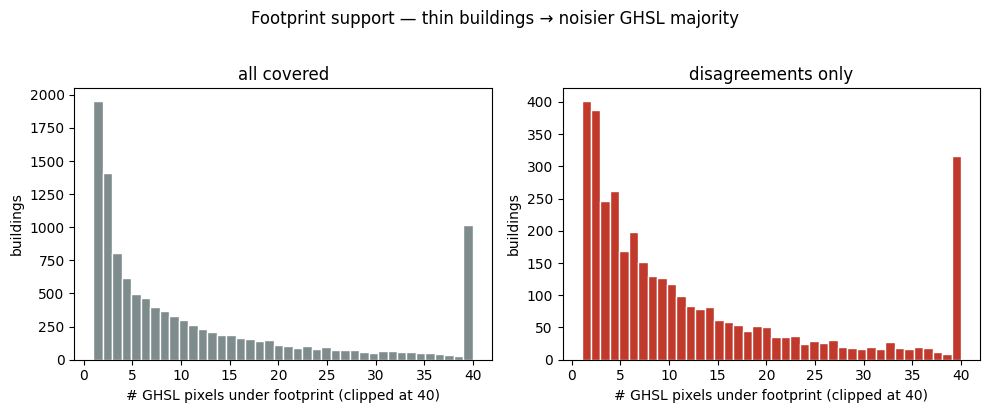

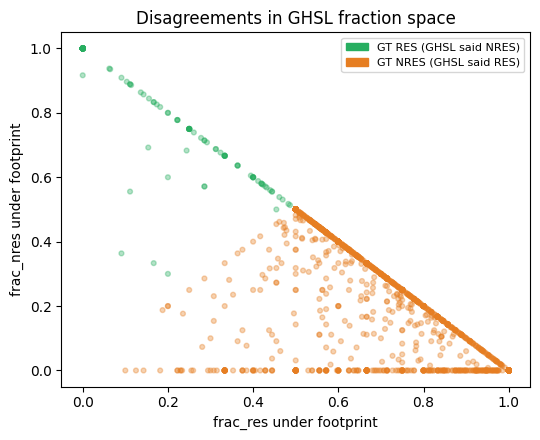

wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/ghsl_eda/disagreement_sample.parquet


In [9]:
dis = covered[covered["gt_label"] != covered["ghsl_prediction"]].copy()
print("disagreements", len(dis), f"({len(dis)/len(covered):.1%} of covered)")
print("swap direction:")
display(pd.crosstab(dis["gt_label"], dis["ghsl_prediction"]))

# Pixel support under the footprint
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, df_, title, color in [
    (axes[0], covered, "all covered", "#7f8c8d"),
    (axes[1], dis, "disagreements only", "#c0392b"),
]:
    ax.hist(df_["n_pixels"].clip(upper=40), bins=40, color=color, edgecolor="white")
    ax.set_xlabel("# GHSL pixels under footprint (clipped at 40)")
    ax.set_ylabel("buildings")
    ax.set_title(title)
fig.suptitle("Footprint support — thin buildings → noisier GHSL majority", y=1.02)
fig.tight_layout()
fig.savefig(FIG / "disagreement_pixel_support.png", dpi=140)
plt.show()

# Fraction mix for disagreements
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(dis["frac_res"], dis["frac_nres"], c=dis["gt_label"].map({"RES": "#27ae60", "NRES": "#e67e22"}),
           alpha=0.35, s=12)
ax.set_xlabel("frac_res under footprint")
ax.set_ylabel("frac_nres under footprint")
ax.set_title("Disagreements in GHSL fraction space")
ax.legend(handles=[
    Patch(color="#27ae60", label="GT RES (GHSL said NRES)"),
    Patch(color="#e67e22", label="GT NRES (GHSL said RES)"),
], fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "disagreement_fraction_space.png", dpi=140)
plt.show()

dis_out = dis.sort_values("n_pixels").head(5000)
dis_out.to_parquet(OUT / "disagreement_sample.parquet", index=False)
print("wrote", OUT / "disagreement_sample.parquet")


## 8. Visual overlay — GHSL chip + GT footprints (eyeballs)

Pipeline spirit: spot-check that GHSL codes look like the buildings we labeled.
We draw one chip per AOI around a random disagreement (or random building if none).


/tmp/ipykernel_506480/952041059.py:43: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  chip[chip["label"] == "RES"].boundary.plot(ax=ax, color="#2ecc71", linewidth=1.2)


/tmp/ipykernel_506480/952041059.py:43: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  chip[chip["label"] == "RES"].boundary.plot(ax=ax, color="#2ecc71", linewidth=1.2)


/tmp/ipykernel_506480/952041059.py:43: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  chip[chip["label"] == "RES"].boundary.plot(ax=ax, color="#2ecc71", linewidth=1.2)
/tmp/ipykernel_506480/952041059.py:43: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  chip[chip["label"] == "RES"].boundary.plot(ax=ax, color="#2ecc71", linewidth=1.2)


/tmp/ipykernel_506480/952041059.py:43: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  chip[chip["label"] == "RES"].boundary.plot(ax=ax, color="#2ecc71", linewidth=1.2)


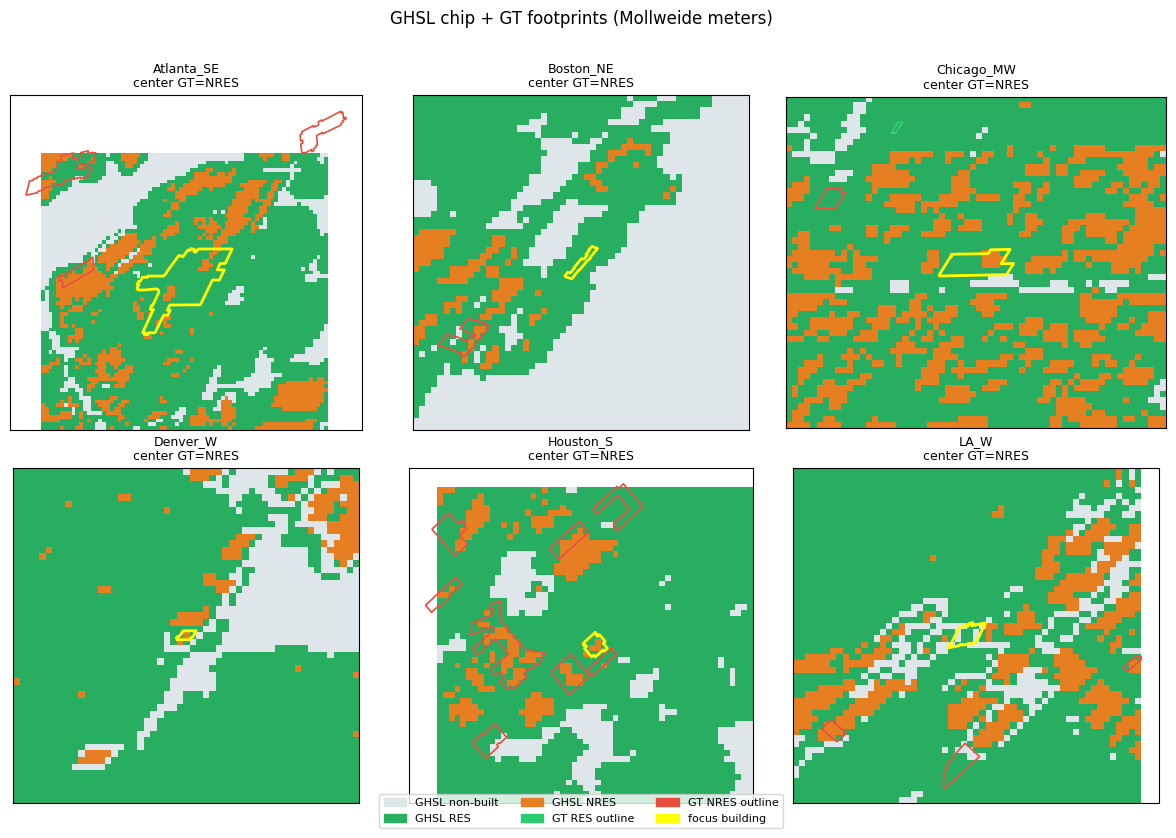

In [10]:
cmap = ListedColormap([GHSL_COLORS[0], GHSL_COLORS[1], GHSL_COLORS[2], GHSL_COLORS[255]])
# Map values 0,1,2,255 -> 0,1,2,3 for plotting
def _encode(a: np.ndarray) -> np.ndarray:
    out = np.full(a.shape, 3, dtype=np.uint8)
    out[a == 0] = 0
    out[a == 1] = 1
    out[a == 2] = 2
    out[a == 255] = 3
    return out


rng = np.random.default_rng(cfg.get("seed", 42))
aois = sorted(gt_m["aoi_id"].unique())
n_show = min(6, len(aois))
pick_aois = list(aois[:n_show])

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.ravel()
for ax, aoi_id in zip(axes, pick_aois):
    sub = gt_m[gt_m["aoi_id"] == aoi_id]
    # Prefer a disagreement building for the chip center
    d_ids = set(dis.loc[dis["aoi_id"] == aoi_id, "building_id"]) if "aoi_id" in dis.columns else set()
    if d_ids:
        center_row = sub[sub["building_id"].isin(d_ids)].iloc[0]
    else:
        center_row = sub.iloc[int(rng.integers(0, len(sub)))]
    geom = center_row.geometry
    minx, miny, maxx, maxy = geom.bounds
    pad = 250  # meters in Mollweide
    win_bounds = (minx - pad, miny - pad, maxx + pad, maxy + pad)

    tile_name = center_row["tile"]
    with rasterio.open(Path(cfg["paths"]["ghsl_tiles_dir"]) / tile_name) as ds:
        window = from_bounds(*win_bounds, transform=ds.transform)
        data = ds.read(1, window=window)
        transform = ds.window_transform(window)

    ax.imshow(_encode(data), cmap=cmap, vmin=0, vmax=3, interpolation="nearest",
              extent=[win_bounds[0], win_bounds[2], win_bounds[1], win_bounds[3]])
    # footprints in chip
    chip = sub.cx[win_bounds[0]:win_bounds[2], win_bounds[1]:win_bounds[3]]
    chip.boundary.plot(ax=ax, color="white", linewidth=0.6)
    chip[chip["label"] == "RES"].boundary.plot(ax=ax, color="#2ecc71", linewidth=1.2)
    chip[chip["label"] == "NRES"].boundary.plot(ax=ax, color="#e74c3c", linewidth=1.2)
    gpd.GeoSeries([geom], crs=gt_m.crs).boundary.plot(ax=ax, color="yellow", linewidth=2.0)
    ax.set_title(f"{aoi_id}\ncenter GT={center_row.label}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

for ax in axes[len(pick_aois):]:
    ax.axis("off")

fig.legend(handles=[
    Patch(color=GHSL_COLORS[0], label="GHSL non-built"),
    Patch(color=GHSL_COLORS[1], label="GHSL RES"),
    Patch(color=GHSL_COLORS[2], label="GHSL NRES"),
    Patch(color="#2ecc71", label="GT RES outline"),
    Patch(color="#e74c3c", label="GT NRES outline"),
    Patch(color="yellow", label="focus building"),
], loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("GHSL chip + GT footprints (Mollweide meters)", y=1.01)
fig.tight_layout()
fig.savefig(FIG / "aoi_ghsl_chips.png", dpi=140, bbox_inches="tight")
plt.show()


## 9. Pixel-level rules you must not forget (pipeline §7–§9)

When you move from building majority to the **10 m pixel benchmark**:

1. Rasterize GT polygons onto the **exact GHSL grid** (same transform / origin).
2. Keep a pixel only if building footprint overlap ≥ `minimum_building_fraction` (default **0.5**).
3. If multiple buildings overlap a pixel → largest footprint area wins; near-ties optional ambiguous.
4. Exclude `MIXED` / `UNKNOWN` / ambiguous pixels.
5. Sample GHSL by **direct cell read** — no resample, no center shift.
6. Rasterize **model** predictions with the identical procedure.

Config knobs live in `validation/config.yaml` (`pixel_validation.minimum_building_fraction`, etc.).


pixel_validation config:
{
  "enabled": true,
  "minimum_building_fraction": 0.5,
  "ambiguous_tie_eps": 0.05
}
building_validation config:
{
  "enabled": true,
  "aggregation": "area_weighted_majority"
}
spatial_independence config:
{
  "enabled": true,
  "buffer_km": 10.0,
  "refuse_held_out_label_on_leakage": true
}
buildings with footprint area < 50 m²: 287 / 11280 (2.5%)
These are the ones most likely to fail the 50% pixel-overlap gate or fall back to centroid sampling.


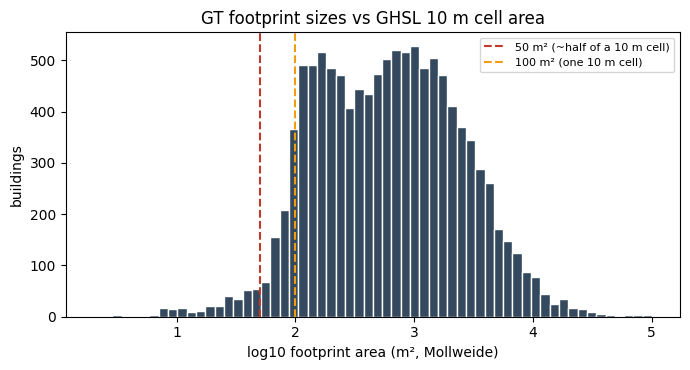

In [11]:
print("pixel_validation config:")
print(json.dumps(cfg["pixel_validation"], indent=2))
print("building_validation config:")
print(json.dumps(cfg["building_validation"], indent=2))
print("spatial_independence config:")
print(json.dumps(cfg.get("spatial_independence", {}), indent=2))

# Show how many buildings are "thin" relative to a 10 m cell (area < 50 m² ⇒ hard to hit ≥50% of a cell)
areas_m2 = gt_m.to_crs(cfg["ghsl"]["crs"]).geometry.area
thin = (areas_m2 < 50).sum()
print(f"buildings with footprint area < 50 m²: {int(thin)} / {len(gt_m)} ({thin/len(gt_m):.1%})")
print("These are the ones most likely to fail the 50% pixel-overlap gate or fall back to centroid sampling.")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(np.log10(np.clip(areas_m2, 1, None)), bins=60, color="#34495e", edgecolor="white")
ax.axvline(np.log10(50), color="#c0392b", ls="--", label="50 m² (~half of a 10 m cell)")
ax.axvline(np.log10(100), color="#f39c12", ls="--", label="100 m² (one 10 m cell)")
ax.set_xlabel("log10 footprint area (m², Mollweide)")
ax.set_ylabel("buildings")
ax.set_title("GT footprint sizes vs GHSL 10 m cell area")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "gt_footprint_area_hist.png", dpi=140)
plt.show()


## 10. Pre-model checklist (what you should be able to say out loud)

After this EDA you should be able to answer:

1. **Product** — GHS-BUILT-C FUN 2018 @ 10 m Mollweide; codes 0/1/2/255; categorical.
2. **GT** — AOI count, RES/NRES balance, no silent MIXED remaps, geometries valid.
3. **Coverage** — almost every building gets a GHSL RES/NRES call here; abstentions are rare but counted in end-to-end.
4. **Two numbers** — functional (covered) vs end-to-end (abstentions hurt).
5. **Geography** — per-AOI GHSL accuracy varies; do not quote one national number as universal.
6. **Disagreements** — RES↔NRES swaps exist; thin footprints are fragile.
7. **Pixel gate** — ≥50% overlap on the *GHSL* grid before a pixel enters the pixel benchmark.
8. **Scoreboard** — headline **macro-F1**; class PRF uses RES as positive (§6b).

When that story is clear, run the full scorer:

```bash
.venv/bin/python scripts/prepare_ghsl_validation_inputs.py   # if GT/preds stale
.venv/bin/python validation/run_validation.py
```

Outputs land in `outputs/validation/` (comparison tables, bootstrap, disagreement GPKG, figures).


In [12]:
snapshot = {
    "notebook": "notebooks/10_ghsl_built_c_validation_eda.ipynb",
    "doc": "docs/ghsl_validation_pipeline.md",
    "product": "GHS-BUILT-C FUN R2023A 2018 10m ESRI:54009",
    "binary_framing": "headline macro-F1; class PRF uses RES = positive (no NRES-as-positive panel)",
    "n_tiles": int(len(tile_meta)),
    "n_buildings": int(len(gt)),
    "n_aois": int(gt["aoi_id"].nunique()),
    "gt_label_counts": {k: int(v) for k, v in audit["label_counts"].items()},
    "ghsl_coverage_building": float(pb["ghsl_covered"].mean()),
    "ghsl_functional": m_ghsl,
    "model_building": m_model,
    "end_to_end_ghsl": e2e_ghsl,
    "end_to_end_model": e2e_model,
    "cnn_vs_ghsl_macro_f1": macro_fun.reset_index().to_dict(orient="records"),
    "cnn_vs_ghsl_res_positive": res_fun.reset_index().to_dict(orient="records"),
    "cnn_vs_ghsl_nres_positive": nres_fun.reset_index().to_dict(orient="records"),
    "paths": {
        "tiles": cfg["paths"]["ghsl_tiles_dir"],
        "gt": cfg["paths"]["gt_buildings"],
        "predictions": cfg["paths"]["model_predictions"],
        "per_building": str(pb_path),
        "outputs": str(OUT),
    },
    "figures": sorted(str(p.relative_to(ROOT)) for p in FIG.glob("*.png")),
}
(OUT / "snapshot.json").write_text(json.dumps(snapshot, indent=2))
print(json.dumps(snapshot, indent=2))
print("\nSaved figures:")
for p in sorted(FIG.glob("*.png")):
    print(" -", p.relative_to(ROOT))


{
  "notebook": "notebooks/10_ghsl_built_c_validation_eda.ipynb",
  "doc": "docs/ghsl_validation_pipeline.md",
  "product": "GHS-BUILT-C FUN R2023A 2018 10m ESRI:54009",
  "binary_framing": "headline macro-F1; class PRF uses RES = positive (no NRES-as-positive panel)",
  "n_tiles": 9,
  "n_buildings": 11280,
  "n_aois": 10,
  "gt_label_counts": {
    "NRES": 8191,
    "RES": 3089
  },
  "ghsl_coverage_building": 0.9932624113475177,
  "ghsl_functional": {
    "n": 11204,
    "accuracy": 0.6787754373438057,
    "res_precision": 0.4578332034294622,
    "res_recall": 0.960431654676259,
    "res_f1": 0.6200781167528765
  },
  "model_building": {
    "n": 11280,
    "accuracy": 0.798581560283688,
    "res_precision": 0.6404262633207288,
    "res_recall": 0.6031078018776304,
    "res_f1": 0.6212070690230078
  },
  "end_to_end_ghsl": {
    "n": 11280,
    "coverage": 0.9932624113475177,
    "selective_accuracy": 0.6787754373438057,
    "effective_accuracy": 0.6742021276595744
  },
  "end_to_en

## Saved figures (no re-run needed)

![GT balance](../outputs/ghsl_eda/figures/gt_class_balance.png)

![Tile built counts](../outputs/ghsl_eda/figures/tile_built_class_counts.png)

![Per-AOI GHSL vs model](../outputs/ghsl_eda/figures/per_aoi_ghsl_vs_model.png)

![Disagreement support](../outputs/ghsl_eda/figures/disagreement_pixel_support.png)

![Disagreement fractions](../outputs/ghsl_eda/figures/disagreement_fraction_space.png)

![AOI chips](../outputs/ghsl_eda/figures/aoi_ghsl_chips.png)

![Footprint areas](../outputs/ghsl_eda/figures/gt_footprint_area_hist.png)


## Pixel-eval method visuals

How the pixel scoreboard is built (center-in-polygon on the GHSL grid). Figures regenerated by `scripts/plot_ghsl_pixel_eval_method.py`.

Boston audit chip: 242 eval cells; 2.48% with true area &lt; 0.5; agree 79 / disagree 153.

![Schematic](../outputs/validation/figures/ghsl_pixel_eval_schematic.png)

![Real chip](../outputs/validation/figures/ghsl_pixel_eval_real_chip.png)

![Agree / disagree](../outputs/validation/figures/ghsl_pixel_eval_agree_disagree.png)

![Center vs area](../outputs/validation/figures/ghsl_pixel_eval_center_vs_area.png)
